# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True

import warnings
warnings.filterwarnings("ignore", category=UserWarning)


[Qibo 0.2.12|ERROR|2025-04-07 05:14:15]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|ERROR|2025-04-07 05:14:15]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|INFO|2025-04-07 05:14:15]: Using numpy backend on /CPU:0


In [3]:
# Step size ptimization
from scipy.optimize import minimize

In [4]:
def max_excitation(thetas, fidelity, target_fidelity, initial_tolerance=1e-5, max_tolerance=0.2, step=1e-3):
    """
    Find the x value corresponding to y = target_fidelity within an adjustable tolerance.
    If not found, increase tolerance gradually up to max_tolerance.
    """
    tolerance = initial_tolerance
    while tolerance <= max_tolerance:
        for xi, yi in zip(thetas, fidelity):
            if abs(yi - target_fidelity) <= tolerance:
                return xi
        tolerance += step
    return None  # or raise an error if no match is acceptable


In [5]:
optimal_s = []
# results = []
for k in range(1,7):
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        return GCI(QITE_dme_select_M(50), psi0, None, optimal_s + [s]).execute_gci()[0][-1].real

    result = minimize(dbqite, 0.7, method='BFGS')
    optimal_s = optimal_s + [result.x[0]]
    # results.append(GCI(QITE_dme_select_M(50), psi0, None, optimal_s).execute_gci()[0][-1].real)

In [6]:
optimal_s

[0.9521378559471058,
 0.741707887460698,
 0.7103699418765648,
 0.7130706347071362,
 0.7267722785876234,
 0.7526541730362077]

In [7]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)

res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for k in range(1,7):
    print(k)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(50), psi0, None, optimal_s[:k]).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'k={k}' : res_DBQITE})

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [8]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


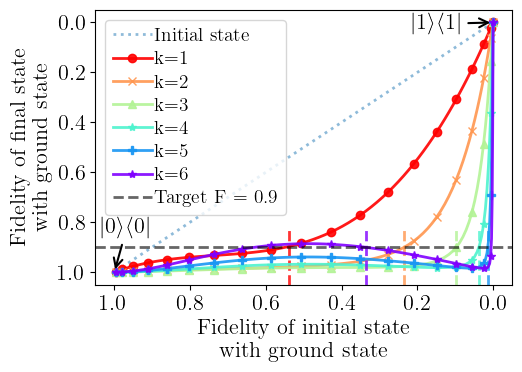

In [9]:
state_0 = np.array([1, 0], dtype=complex)
def fidelity_with_0(state):
    shape = np.shape(state)
    if shape[0] == shape[1]:
        return np.real(np.conj(state_0).T @ state @ state_0)
    else:
        dm = state@state.T.conj()
        return np.real(np.conj(state_0).T @ dm @ state_0)
    
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
color = cm.rainbow(np.linspace(1, 0, 6))

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state", alpha=0.5,linestyle=':')

i=0
markers = ['o','x','^','*','P','*','h']
for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    i+=1

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}',linestyle='--')
ax.legend()

ax.annotate(r'$|1\rangle\langle 1|$', 
            xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.08, fidelity[0]+0.05), 
            arrowprops=dict(arrowstyle='->', lw=1.5),
            ha='right', va='bottom')

ax.annotate(r'$|0\rangle\langle 0|$',
            xy=(fidelities_original[-1], fidelity[-1]),  # Point to the data
            xytext=(fidelities_original[-1] - 0.1, fidelity[-1] - 0.22),  # Text location
            arrowprops=dict(arrowstyle='->', lw=1.5),
            ha='right', va='top')

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_M_50_fidelity_final_vs_original.pdf')


In [10]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)

res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for k in range(1,7):
    print(k)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(ideal_DME, psi0, None, optimal_s[:k]).execute_gci()[0][-1])
        dict_res_DBQITE.update({f'k={k}' : res_DBQITE})

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [11]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

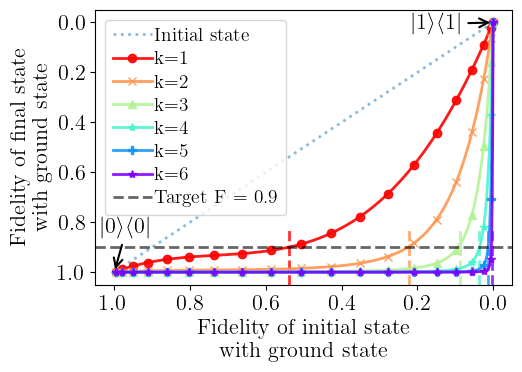

In [12]:
state_0 = np.array([1, 0], dtype=complex)
def fidelity_with_0(state):
    shape = np.shape(state)
    if shape[0] == shape[1]:
        return np.real(np.conj(state_0).T @ state @ state_0)
    else:
        dm = state@state.T.conj()
        return np.real(np.conj(state_0).T @ dm @ state_0)
    
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
color = cm.rainbow(np.linspace(1, 0, 6))

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state", alpha=0.5,linestyle=':')

i=0
markers = ['o','x','^','*','P','*','h']
for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    i+=1

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}',linestyle='--')
ax.legend()


ax.annotate(r'$|1\rangle\langle 1|$', 
            xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.08, fidelity[0]+0.05), 
            arrowprops=dict(arrowstyle='->', lw=1.5),
            ha='right', va='bottom')

ax.annotate(r'$|0\rangle\langle 0|$',
            xy=(fidelities_original[-1], fidelity[-1]),  # Point to the data
            xytext=(fidelities_original[-1] - 0.1, fidelity[-1] - 0.22),  # Text location
            arrowprops=dict(arrowstyle='->', lw=1.5),
            ha='right', va='top')

plt.tight_layout()
plt.savefig(f'plots/QITE_ideal_DME_fidelity_final_vs_original.pdf')


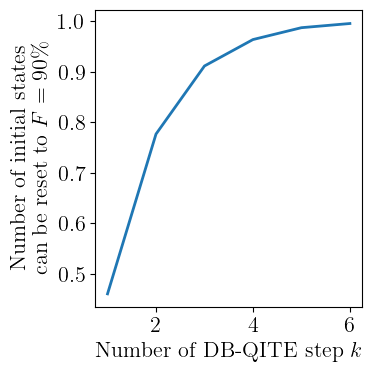

In [ ]:
plt.figure(figsize=(4,4))
plt.plot(range(1,7),[1-max_ext for max_ext in max_ext_list])
plt.xlabel(r'Number of DB-QITE step $k$')
plt.ylabel('Number of initial states \n' + r'can be reset to $F=90\%$')
plt.tight_layout()

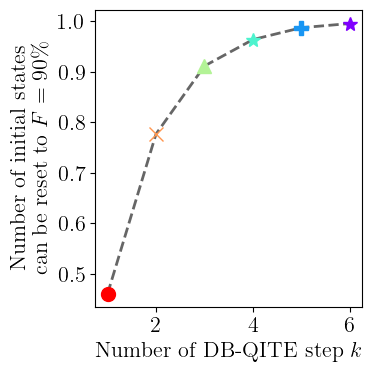

In [40]:
markers = ['o','x','^','*','P','*','h']
colors = cm.rainbow(np.linspace(1, 0, len(max_ext_list)))

plt.figure(figsize=(4, 4))

x_vals = range(1, len(max_ext_list) + 1)
y_vals = [1 - max_ext for max_ext in max_ext_list]

plt.plot(range(1,7),[1-max_ext for max_ext in max_ext_list], color='k', alpha=0.6,linestyle='--')

for i, (x, y) in enumerate(zip(x_vals, y_vals)):
    plt.plot(x, y, marker=markers[i % len(markers)], color=colors[i], markersize=10, linestyle='None')

plt.xlabel(r'Number of DB-QITE step $k$')
plt.ylabel('Number of initial states \n' + r'can be reset to $F=90\%$')
plt.tight_layout()
plt.savefig(f'plots/QITE_ideal_DME_number_init_state.pdf')
plt.show()